# Phase 2 — Exploratory analysis of washing-machine use (official cleaned REFIT data)

**Goal:** describe how washing machines are used in several UK homes, at 1-minute resolution, using the
**official cleaned REFIT files** (`Data/CLEAN_REFIT_081116/`). This notebook is independent of Phase 1 —
it reads none of Phase 1's outputs.

All logic lives in [`wm_eda.py`](wm_eda.py); this notebook calls those functions step by step and explains
each decision. `python3 phase2/wm_eda.py` produces exactly the same tables and figures in one go.

| Output | Location |
|---|---|
| 1-minute processed data (per house) | `Data/processed/phase2/house{N}_wm_1min.parquet` |
| Tables | `outputs/tables/phase2/` |
| Figures | `outputs/figures/phase2/` |

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# Make wm_eda importable whether the notebook runs from the repo root or from phase2/
here = Path.cwd()
sys.path.insert(0, str(here if (here / "wm_eda.py").exists() else here / "phase2"))
import wm_eda as w

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
w.ensure_dirs()
print("Repository root:", w.ROOT.name)
print("Cleaned data   :", w.CLEAN_DIR.relative_to(w.ROOT), "-", len(list(w.CLEAN_DIR.glob('CLEAN_House*.csv'))), "files")

Repository root: FlowEnergy_001
Cleaned data   : Data/CLEAN_REFIT_081116 - 20 files


## 1 · Dataset and channel selection

The cleaned REFIT release has one CSV per house (`Time, Unix, Aggregate, Appliance1…9, Issues`).
Which `ApplianceN` column is the washing machine differs per house, so the mapping comes from the
**official readme** (`CLEAN_READ_ME_081116.txt`, copy saved in `docs/`).

Selection rule: use houses whose readme entry names **one dedicated "Washing Machine"** with **no change
note** during the study. Six houses qualify and were chosen to span different occupancies (1–4 people):
Houses 2, 5, 7, 8, 9 and 15. Houses with ambiguous laundry channels were excluded (table below).

> **Assumption:** the readme's appliance list is correct for the whole record. The readme itself warns that
> occupants may have moved IAM plugs; the cleaned release says it re-aligned such moves, but this cannot be
> verified independently here.

> **Limitation (House 5):** the readme labels House 5 `Appliance3` as "Washing Machine, AEG, L99695HWD".
> That model number appears to be a *washer-dryer*, and the data contain several activity periods of 5–9.5 h
> with ~2.2 kW heater peaks — longer than any wash cycle seen in the other houses, consistent with a wash followed
> by drying (shown in §4). House 5 is kept, but its cycle statistics may mix wash and dry phases.

In [2]:
mapping = w.mapping_table()
mapping

,house,wm_channel,readme_label,occupancy,selected,note
0,2,Appliance2,"Washing Machine, LG, F1289TD",4.0,True,
1,5,Appliance3,"Washing Machine, AEG, L99695HWD",4.0,True,Model AEG L99695HWD appears to be a washer-dry...
2,7,Appliance5,"Washing Machine, Bosch, Unknown",4.0,True,
3,8,Appliance4,"Washing Machine, (no make/model given)",2.0,True,
4,9,Appliance3,"Washing Machine, Bosch, Classixx 6 1200 Express",2.0,True,
5,15,Appliance3,"Washing Machine, Beko, WMB91242LB",1.0,True,
6,1,,,NaN,False,Two laundry channels (Washer Dryer + Washing M...
7,4,,,NaN,False,Two washing machines (Appliance4 and Appliance5)
8,13,,,NaN,False,Readme notes the washing machine 'Changes 25 M...
9,12,,,NaN,False,No washing machine listed (several channels la...


## 2 · Loading and minimal preparation

Steps applied to each house (raw CSVs are never modified):

1. **Read only the needed columns** (`Unix`, `Aggregate`, washing-machine channel, `Issues`).
2. **Sort by `Unix` and drop duplicate timestamps** (keep first). The cleaned files turned out to be
   already sorted and duplicate-free (see check table) — this is a safety net.
3. **Mask frozen readings.** The cleaned release forward-fills missing values, so a sensor that stops
   reporting can appear as one value repeated for hours. A real washing machine's power always fluctuates,
   so an identical **non-zero** value (> 20 W) held for **> 60 min** is set to missing. For the aggregate,
   *any* identical value held > 60 min is masked (a whole house never sits at exactly one wattage that long).
4. **Resample to 1-minute means.** Minutes without a valid reading stay `NaN`.

> **Assumption:** `Unix` is UTC (readme: "UNIX TIMESTAMP (UCT)"); the `Time` column was found to equal `Unix`
> exactly, so it is also UTC. Behavioural analysis (hour of day, weekday) converts to **Europe/London** local time.

> **Assumption:** readings arrive every ~6–8 s, so a plain arithmetic mean of the ~8 readings in each minute
> is used as that minute's power. This is close to a time-weighted mean when sampling is this regular.

> **Missing data rule:** a missing minute is *unknown*, never zero. It is never counted as "machine off".

In [3]:
minute, checks = w.prepare_all(save=True)
checks

,house,file,raw_rows,nan_values,non_monotonic_steps,duplicate_unix,negative_values,wm_max_w,aggregate_max_w,wm_frozen_samples,aggregate_frozen_samples,wm_frozen_minutes
0,2,CLEAN_House2.csv,5733526,0,0,0,0,3584.0,24595.0,0,31699,0
1,5,CLEAN_House5.csv,7430755,0,0,0,0,2437.0,41738.0,160417,5880,17228
2,7,CLEAN_House7.csv,6756034,0,0,0,0,3584.0,32730.0,92,8705,0
3,8,CLEAN_House8.csv,6118469,0,0,0,0,3972.0,25358.0,0,34361,0
4,9,CLEAN_House9.csv,6169525,0,0,0,0,2484.0,28836.0,0,319996,0
5,15,CLEAN_House15.csv,6225696,0,0,0,0,3336.0,8840.0,2101,27972,225


In [4]:
# Longest stretch per house where the aggregate was masked as frozen but the WM channel still reported
rows = []
for h, m in minute.items():
    s, e = w._runs((m["aggregate_w"].isna() & m["wm_w"].notna()).to_numpy())
    if len(s):
        k = (e - s).argmax()
        rows.append({"house": h, "total_days": round((e - s + 1).sum() / 1440, 1),
                     "longest_start_utc": m.index[s[k]], "longest_days": round((e[k] - s[k] + 1) / 1440, 1)})
pd.DataFrame(rows)

,house,total_days,longest_start_utc,longest_days
0,2,4.5,2014-08-30 14:04:00+00:00,1.8
1,5,0.8,2014-08-01 18:01:00+00:00,0.0
2,7,3.4,2014-08-30 14:02:00+00:00,1.8
3,8,5.5,2014-08-30 13:57:00+00:00,1.8
4,9,26.7,2014-03-19 19:08:00+00:00,4.6
5,15,4.6,2014-09-05 21:36:00+00:00,1.9


> **Limitation:** frozen-value masking only catches stuck periods longer than 60 minutes. Shorter
> forward-filled stretches are indistinguishable from genuine steady readings and remain in the data.
> House 9's aggregate is the notable case above: it is stuck at one value for weeks in total during spring 2014
> while the washing-machine channel keeps reporting. Several houses also share a frozen-aggregate stretch
> starting 2014-08-30, again pointing to a study-wide collection fault. This does not affect the washing-machine EDA, but matters for
> Phase 3, which models the aggregate.

## 3 · Data quality and availability

In [5]:
quality = w.quality_summary(minute)
gaps = pd.concat([w.gap_table(m, h) for h, m in minute.items()], ignore_index=True)
daily = w.daily_availability(minute)
quality.set_index("house").T

house,2,5,7,8,9,15
wm_channel,Appliance2,Appliance3,Appliance5,Appliance4,Appliance3,Appliance3
start_utc,2013-09-17 22:08:00+00:00,2013-09-26 09:56:00+00:00,2013-11-01 22:01:00+00:00,2013-11-01 22:13:00+00:00,2013-12-17 17:26:00+00:00,2013-12-17 17:24:00+00:00
end_utc,2015-05-28 08:05:00+00:00,2015-07-06 17:48:00+00:00,2015-07-08 02:10:00+00:00,2015-05-10 23:36:00+00:00,2015-07-08 18:52:00+00:00,2015-07-08 02:10:00+00:00
span_days,617.4,648.3,613.2,555.1,568.1,567.4
expected_minutes,889078,933593,882970,799284,818007,817007
valid_wm_minutes,670164,826493,771841,717221,692184,705156
missing_wm_minutes,218914,107100,111129,82063,125823,111851
availability_pct,75.38,88.53,87.41,89.73,84.62,86.31
gaps_total,818,1838,638,638,574,1310
gaps_le_5min,355,963,519,552,495,616


In [6]:
# Longest gaps per house, and gaps that several houses share (network-wide outages)
print(gaps.sort_values("duration_min", ascending=False).groupby("house").head(2).to_string(index=False))
shared = gaps[gaps["duration_days"] > 5].groupby(gaps["gap_start_utc"].dt.date)["house"].apply(list)
print("\nGaps > 5 days, grouped by start date (houses affected):")
print(shared.to_string())

 house             gap_start_utc               gap_end_utc  duration_min  duration_days
     2 2013-10-25 12:10:00+00:00 2013-12-26 12:43:00+00:00         89314          62.02
     2 2013-12-26 16:09:00+00:00 2014-02-13 16:07:00+00:00         70559          49.00
     9 2014-01-24 01:57:00+00:00 2014-03-06 16:22:00+00:00         59906          41.60
     7 2014-01-24 01:57:00+00:00 2014-03-06 16:22:00+00:00         59906          41.60
     8 2014-01-26 14:29:00+00:00 2014-03-06 16:22:00+00:00         56274          39.08
     9 2014-04-12 01:57:00+00:00 2014-04-28 20:25:00+00:00         24149          16.77
    15 2015-05-10 23:37:00+00:00 2015-05-19 15:09:00+00:00         12453           8.65
     7 2015-05-10 23:37:00+00:00 2015-05-19 15:09:00+00:00         12453           8.65
     5 2015-05-10 23:37:00+00:00 2015-05-19 15:09:00+00:00         12453           8.65
     5 2015-06-10 13:19:00+00:00 2015-06-18 01:38:00+00:00         10820           7.51
    15 2015-06-10 13:19:00+00:00

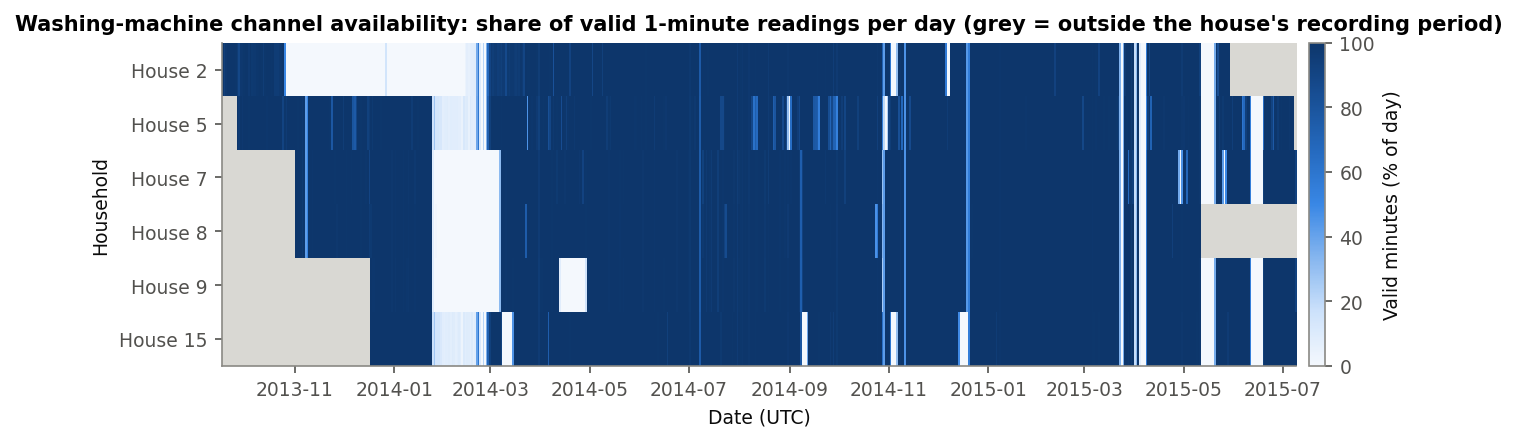

In [7]:
display(Image(filename=str(w.fig_availability(daily))))

**Interpretation.** Several gaps start or end on the *same dates in several houses* — Houses 7, 8 and 9 lose
about six weeks ending on the same day in March 2014, and five houses share gaps in May and June 2015. That
points to study-wide collection failures (the readme notes missing data "notably February 2014"), not to
household behaviour. Houses 5 and 15 show only partial data loss in early 2014. House 2 has the lowest
availability because of two back-to-back outages from late 2013 to February 2014.
The `Issues` flag (sub-meters summing to more than the aggregate) affects a few percent of minutes; it concerns
the aggregate/sub-meter relationship, so those minutes are **kept** for the washing-machine EDA but reported.
All availability-dependent rates below are divided by **observed** time.

## 4 · Detecting activity periods and likely wash cycles

**Rule, in plain language**

1. **Active minute:** the washing machine's average power that minute is **above 20 W**.
   Off/standby readings sit at 0–6 W in all six houses; the drum motor alone draws ~50–300 W and the heater
   ~2 kW, so 20 W separates "doing something" from "idle" with a wide margin.
2. **Activity period:** active minutes separated by pauses of **15 minutes or less** are joined.
   Inside a programme the machine pauses briefly between fill, wash, rinse and spin (the pause-length
   distribution is dominated by ≤ 5-min gaps), whereas separate uses are usually hours apart.
3. **Likely wash cycle:** an activity period that looks like a programme — lasts **10–300 min**, uses
   **≥ 0.05 kWh** and peaks **above 200 W**. Everything else is "other activity" (door-lock/pump blips,
   programme selection, or very long merged periods).
4. **Complete vs gap-affected:** a likely cycle with any missing minute inside it or within 15 min of either
   end is flagged *gap-affected* — it may be truncated or split. Counts include them; duration and energy
   statistics use **complete cycles only**.

> **Important distinction:** these are *detected* periods of electrical activity on the washing-machine
> plug. They are **not confirmed physical wash loads** — there is no ground-truth log of loads. Two
> back-to-back loads within 15 min would be merged into one; a long soak pause > 15 min would split one load
> into two; and in House 5 a wash followed by a drying phase may be counted as one or two periods.

In [8]:
act = w.detect_all(minute)
act.groupby(["house", "category"]).size().unstack(fill_value=0)

category,likely cycle (complete),likely cycle (gap-affected),long period (>300 min),short/small activity
house,,,,
2,284,36,0,30
5,569,97,15,398
7,793,40,1,72
8,359,10,0,63
9,233,9,0,23
15,234,14,0,124


In [9]:
# House 5 washer-dryer check: very long periods vs the longest likely cycle elsewhere
long5 = act[(act.house == 5) & (act.category == "long period (>300 min)")]
print(f"House 5 periods > {w.CYCLE_MAX_DURATION_MIN} min: {len(long5)}, "
      f"{long5.duration_min.min()}-{long5.duration_min.max()} min, "
      f"{long5.energy_kwh.min():.2f}-{long5.energy_kwh.max():.2f} kWh, "
      f"from {long5.start_local.min():%Y-%m-%d} to {long5.start_local.max():%Y-%m-%d}")
print("Longest likely cycle in the other houses:",
      act[(act.house != 5) & act.likely_cycle].duration_min.max(), "min")

House 5 periods > 300 min: 15, 305-572 min, 1.34-3.44 kWh, from 2015-02-13 to 2015-05-23
Longest likely cycle in the other houses: 257 min


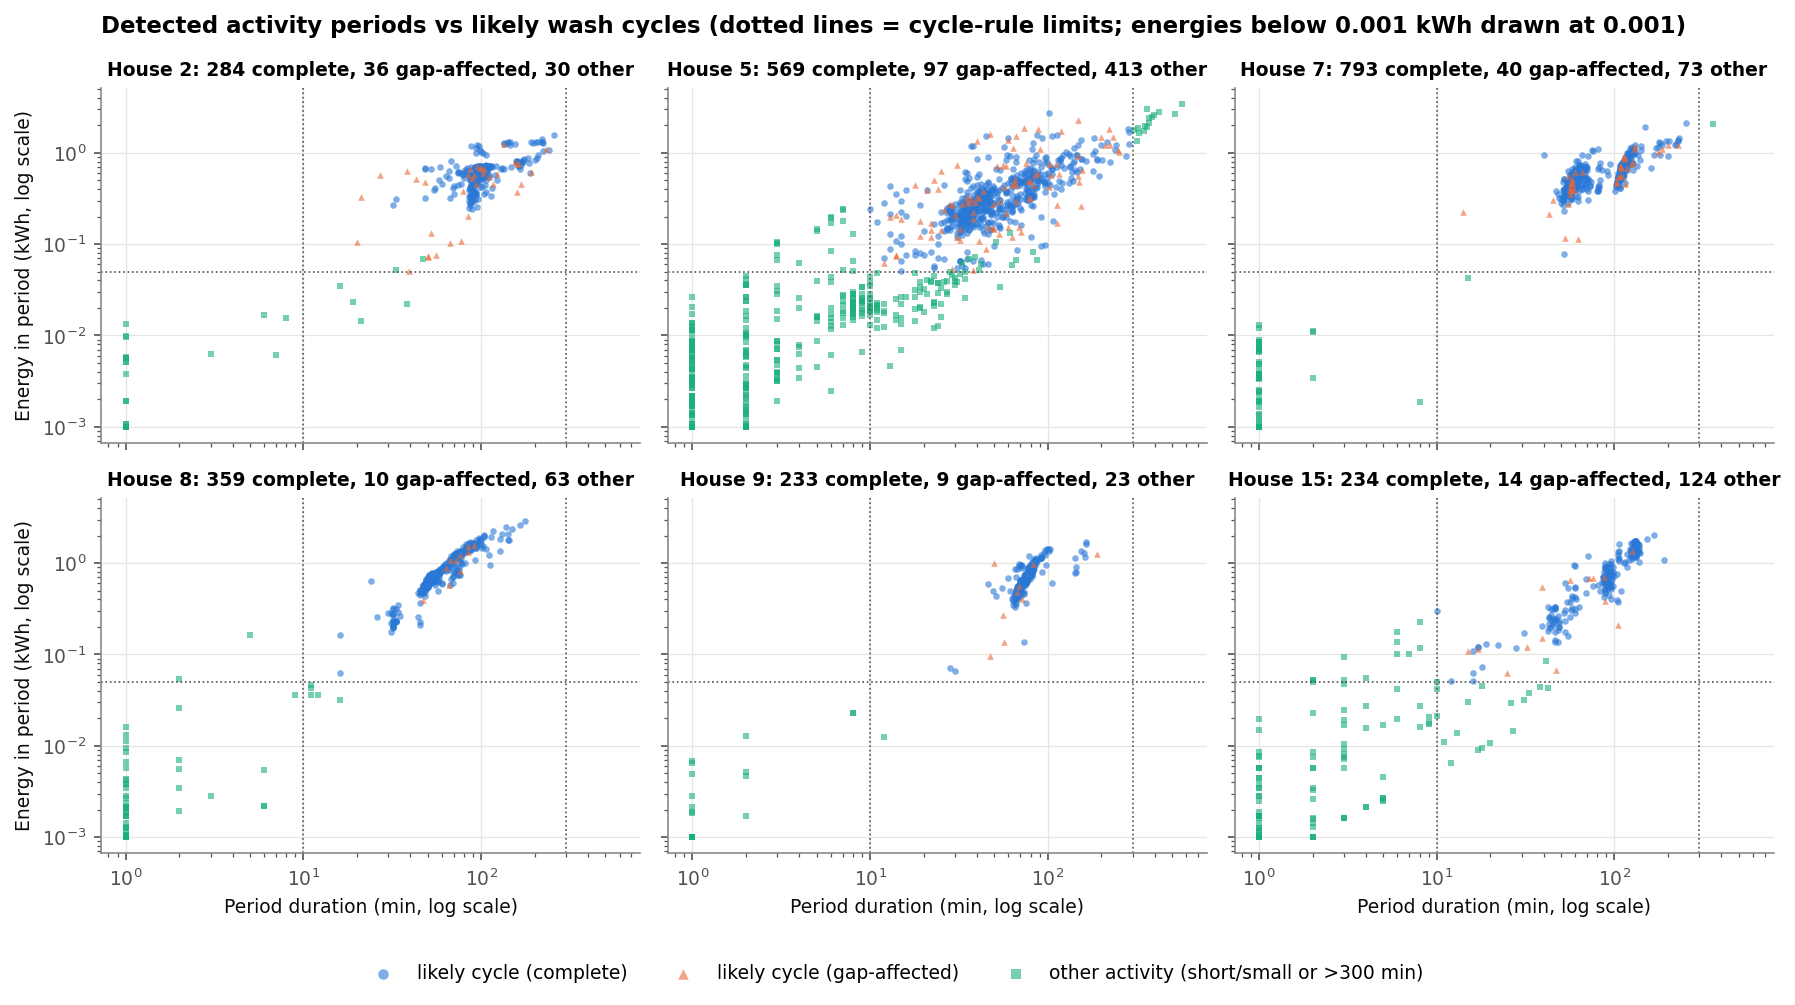

In [10]:
display(Image(filename=str(w.fig_period_classification(act))))

**Interpretation.** In Houses 2, 7, 8 and 9 the likely cycles form one tight cluster (roughly 30–200 min,
0.2–2 kWh) that is far away from the "other" points, so the rule is not sensitive to the exact limits.
Houses 5 and 15 have many short, low-energy periods (blips of 1–10 min), and House 5's points form a
continuous smear from tiny to very long periods — consistent with the washer-dryer concern above.

**Sensitivity check.** The table below recounts likely cycles under other thresholds (10/20/50 W) and pause
lengths (5/10/15/30 min). The power threshold barely matters. The *pause length* matters more in Houses 2, 5
and 7: a short pause rule splits some programmes with long internal pauses into two, a long rule merges
back-to-back loads. Houses 8, 9 and 15 are stable. Houses 7 and 5 remain the two most frequent users under
every setting; the near-tied pairs (Houses 8 vs 2, and 9 vs 15) can swap places, so their ordering should not be
over-interpreted. Absolute cycle counts carry this uncertainty.

In [11]:
sens = w.sensitivity_table(minute)
base = sens[(sens.active_w == w.ACTIVE_W) & (sens.merge_gap_min == w.MERGE_GAP_MIN)].iloc[0]
house_cols = [c for c in sens.columns if c.startswith("house_")]
spread = ((sens[house_cols].max() - sens[house_cols].min()) / base[house_cols] * 100).round(1)
display(sens)
print("Range of likely-cycle counts across all 12 settings, as % of the chosen setting:")
print(spread.to_string())

,active_w,merge_gap_min,house_2,house_5,house_7,house_8,house_9,house_15
0,10.0,5,338.0,719.0,876.0,368.0,248.0,257.0
1,10.0,10,328.0,685.0,849.0,368.0,246.0,254.0
2,10.0,15,318.0,655.0,830.0,368.0,242.0,247.0
3,10.0,30,301.0,596.0,798.0,364.0,233.0,234.0
4,20.0,5,340.0,722.0,879.0,366.0,248.0,253.0
5,20.0,10,333.0,690.0,855.0,364.0,247.0,256.0
6,20.0,15,320.0,666.0,833.0,369.0,242.0,248.0
7,20.0,30,302.0,602.0,798.0,364.0,234.0,235.0
8,50.0,5,375.0,719.0,904.0,366.0,254.0,250.0
9,50.0,10,342.0,708.0,866.0,362.0,247.0,254.0


Range of likely-cycle counts across all 12 settings, as % of the chosen setting:
house_2     23.1
house_5     18.9
house_7     12.7
house_8      1.9
house_9      8.7
house_15     9.3


### Representative 24-hour trace

The day is chosen **by rule**, not by eye: in House 8, a local calendar day with ≥ 95% valid minutes on both
channels containing exactly one complete likely cycle, picking the one whose energy is closest to the
house's median cycle energy.

{'house': 8, 'day': '2014-03-23', 'cycle_start_local': '2014-03-23 05:24:00+00:00', 'duration_min': 57, 'energy_kwh': 0.786, 'peak_w': 2311.0, 'day_aggregate_kwh': 18.37, 'day_wm_kwh': 0.8}
Washing machine share of that day's aggregate energy: 4.4%


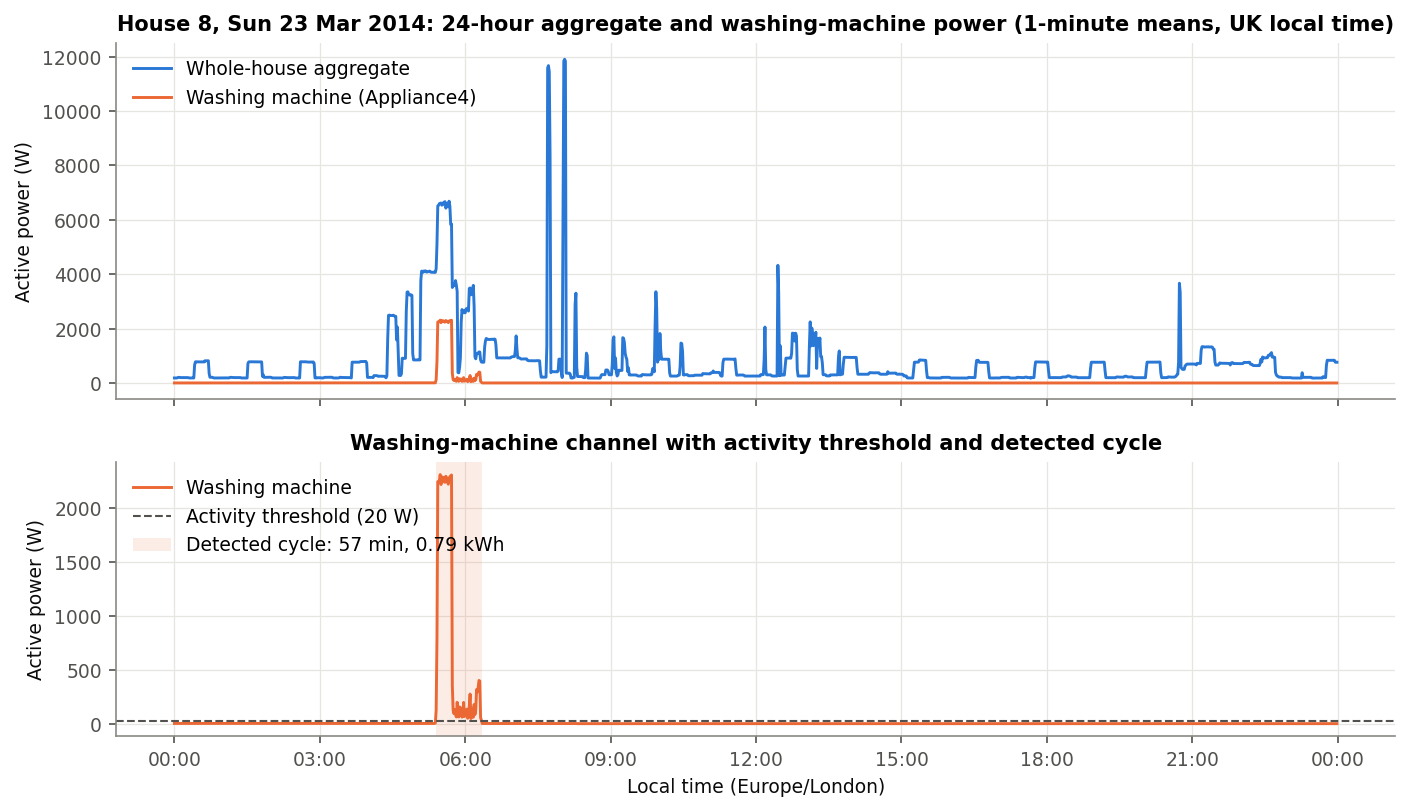

In [12]:
p, rep_day = w.fig_representative_day(minute, act, w.REP_DAY_HOUSE)
print(rep_day)
print(f"Washing machine share of that day's aggregate energy: {100 * rep_day['day_wm_kwh'] / rep_day['day_aggregate_kwh']:.1f}%")
display(Image(filename=str(p)))

**Interpretation.** The washing machine is a short, distinctive event in the day: a ~2.2 kW heating block
at the start of the cycle, followed by a long low-power tail (drum tumbling, rinses, final spin at a few hundred
watts). In the aggregate, the heating block sits on top of other loads (a large load already running when the
machine starts, and short high spikes later in the morning) — the heater phase is visible in the
whole-house signal, but the low-power tail is almost invisible against the background, which is the core
difficulty for Phase 3 disaggregation.

### Representative detected cycles (one per house)

,house,start_local,duration_min,energy_kwh,peak_w,heating_minutes
62,2,2014-04-09 13:49:00+01:00,93,0.637664,2149.000000,15
1160,5,2015-01-01 13:03:00+00:00,37,0.293358,1994.200000,8
1614,7,2014-04-11 18:50:00+01:00,58,0.549331,2083.750000,14
2411,8,2014-03-23 05:24:00+00:00,57,0.786390,2311.400000,18
2946,9,2015-01-10 11:38:00+00:00,79,0.667461,2172.555556,16
3313,15,2015-03-18 03:57:00+00:00,88,0.716649,2278.777778,15


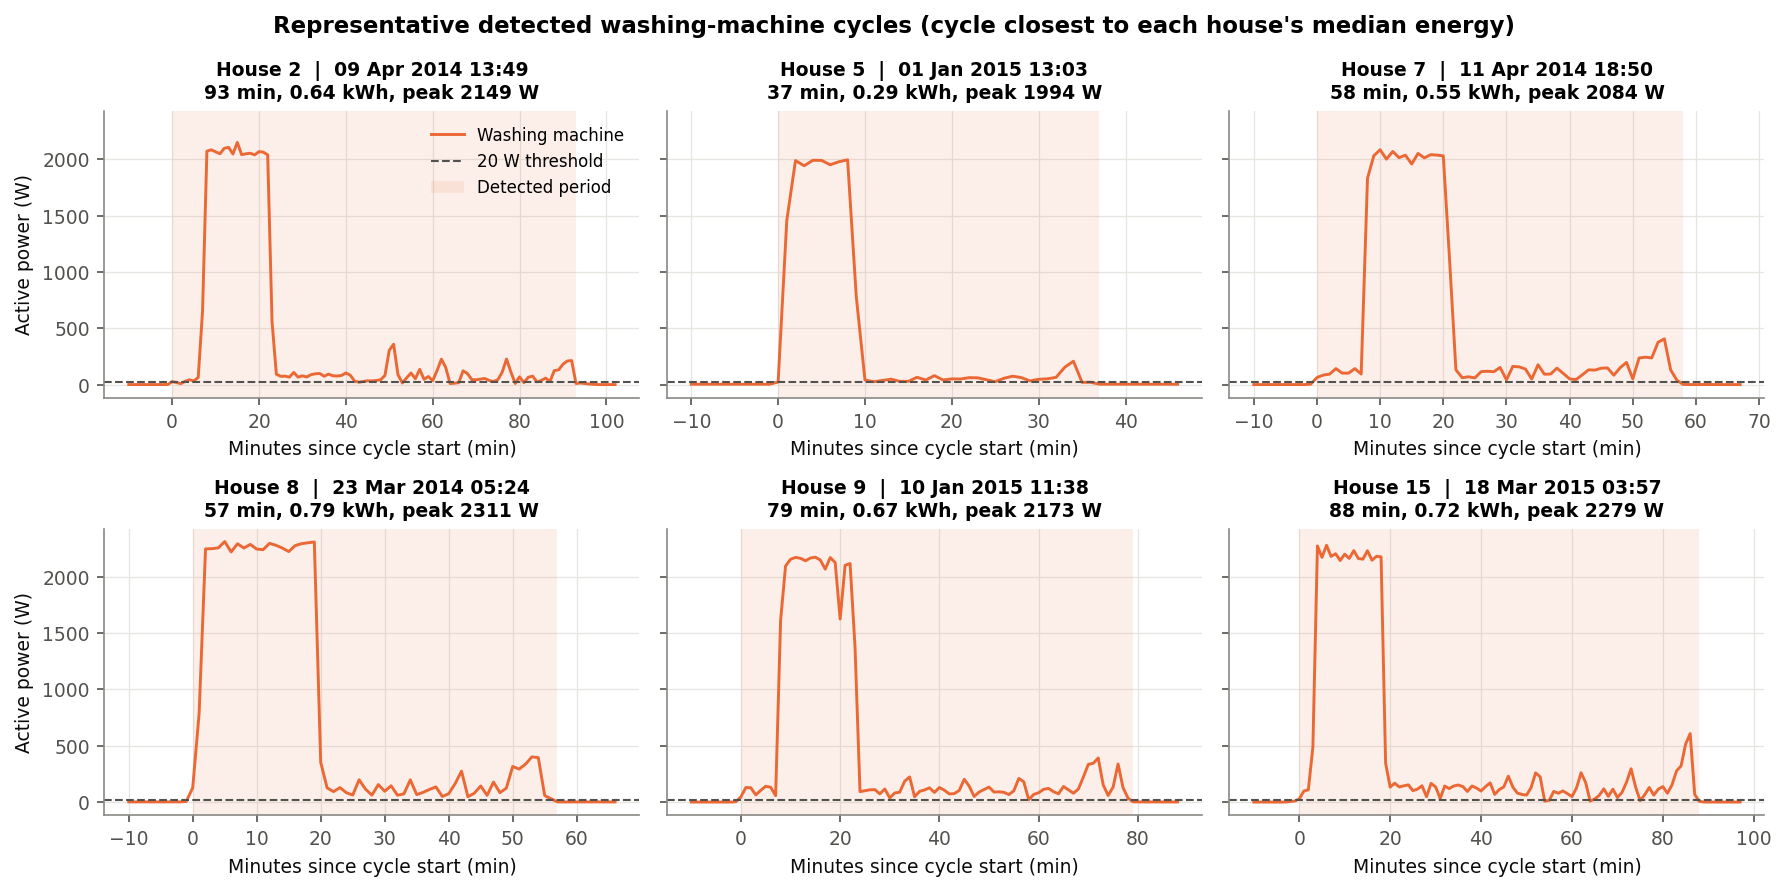

In [13]:
reps = w.representative_cycles(act)
display(reps[["house", "start_local", "duration_min", "energy_kwh", "peak_w", "heating_minutes"]])
display(Image(filename=str(w.fig_representative_cycles(minute, act))))

**Interpretation.** All six "typical" cycles share the same shape: a ~2 kW heating block lasting
roughly 10–20 minutes near the start, then a motor-driven tail with spin peaks towards the end. They differ mainly in total length,
which reflects programme choice and machine model (House 2's LG runs ~1.5 h; House 5's typical cycle is
short). This common heater-then-tail signature is what a disaggregation model can learn.

## 5 · Usage patterns by hour of day and weekday

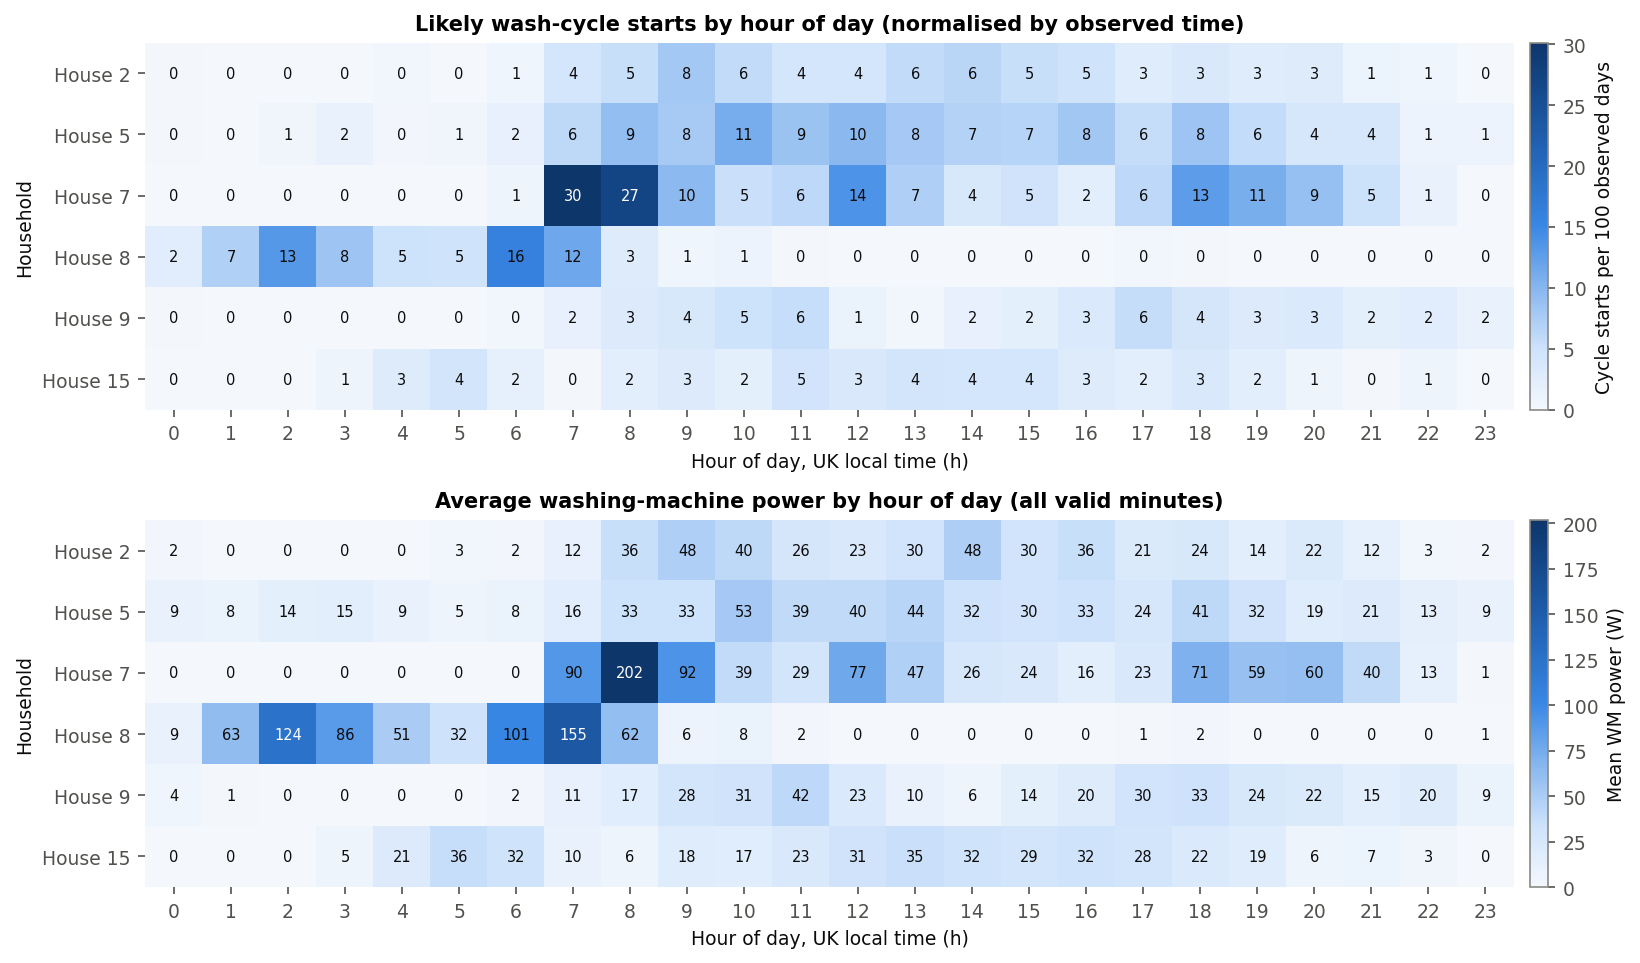

In [14]:
hourly = w.hourly_profile(minute, act)
weekly = w.weekday_profile(minute, act)
display(Image(filename=str(w.fig_hourly(hourly))))

In [15]:
peak = hourly.loc[hourly.groupby("house")["starts_per_100_days"].idxmax(), ["house", "hour_local", "starts_per_100_days"]]
night = (hourly[hourly.hour_local < 7].groupby("house")["cycle_starts"].sum()
         / hourly.groupby("house")["cycle_starts"].sum() * 100).round(1).rename("pct_starts_00_07h")
print(peak.merge(night, on="house").to_string(index=False))

 house  hour_local  starts_per_100_days  pct_starts_00_07h
     2           9             7.980731                1.9
     5          10            11.036496                4.2
     7           7            30.141346                0.5
     8           6            16.076094               77.0
     9          17             5.581972                1.2
    15          11             4.519310               19.4


**Interpretation.** Most houses start cycles during the day, from mid-morning through early evening.
**House 7** has a sharp morning peak (07:00–08:00) and a second evening peak — consistent with a household
washing before and after work. **House 8** is the clear outlier: most of its cycles start between 01:00 and
07:00, which looks like a delay timer or an off-peak (e.g. Economy 7) tariff — the data cannot confirm which.
House 15 also starts a noticeable share of cycles in the early morning (04:00–06:00).
This matters for Phase 4: some households already shift laundry load away from the evening peak.

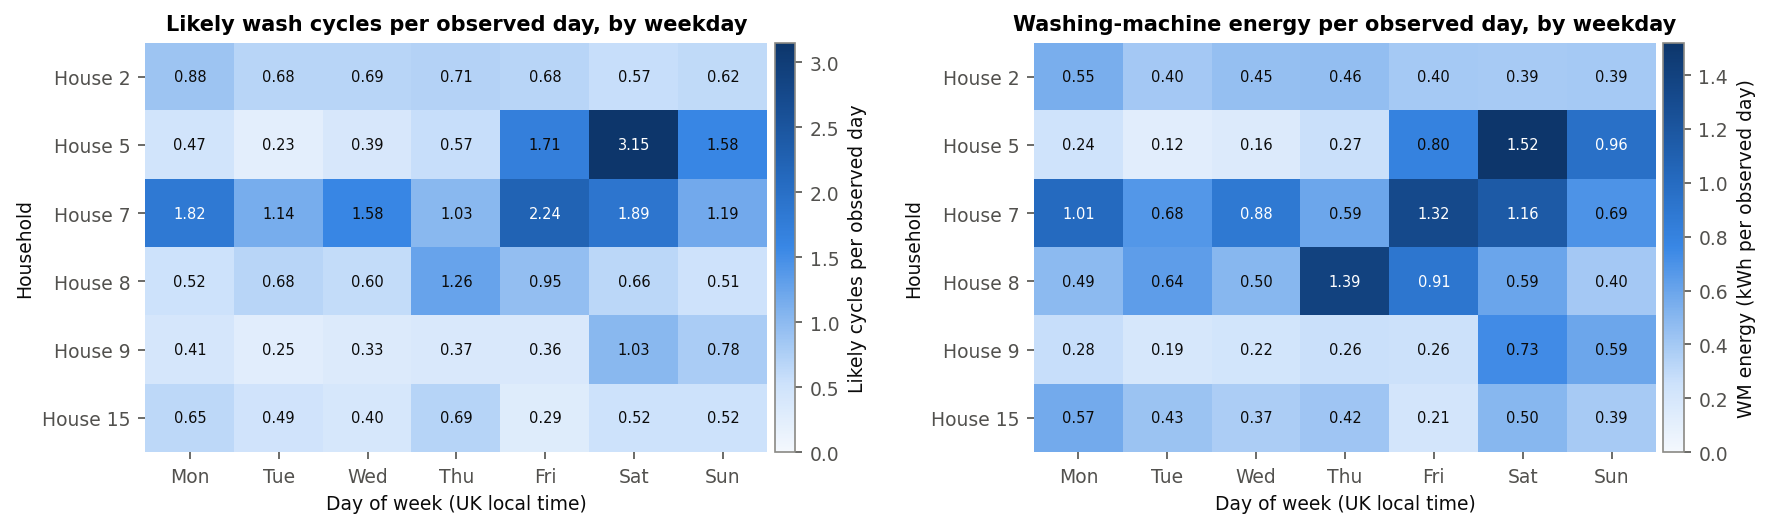

Weekend vs weekday cycle rate (cycles per observed day):
weekend  weekday  weekend  ratio
house                           
2           0.73     0.59   0.82
5           0.67     2.37   3.51
7           1.56     1.54   0.99
8           0.80     0.59   0.73
9           0.34     0.90   2.63
15          0.50     0.52   1.03


In [16]:
display(Image(filename=str(w.fig_weekday(weekly))))
wk = weekly.assign(weekend=weekly.weekday.isin(["Sat", "Sun"]))
ratio = wk.groupby(["house", "weekend"])["cycles_per_observed_day"].mean().unstack()
print("Weekend vs weekday cycle rate (cycles per observed day):")
print(ratio.assign(ratio=(ratio[True] / ratio[False]).round(2)).rename(columns={False: "weekday", True: "weekend"}).round(2).to_string())

**Interpretation.** Weekday patterns are household-specific rather than universal. **Houses 5 and 9** do much
more washing at weekends; **House 8** peaks on Thursday/Friday; **Houses 2, 7 and 15** are fairly evenly
spread. A single "average UK household" weekly profile would therefore hide most of this variation.

## 6 · Cross-household comparison

In [17]:
summary = w.cycle_summary(minute, act)
summary.set_index("house").T

house,2,5,7,8,9,15
occupancy,4.000,4.000,4.000,2.000,2.000,1.000
observed_days,465.400,574.000,536.000,498.100,480.700,489.700
activity_periods,350.000,1079.000,906.000,432.000,265.000,372.000
likely_cycles,320.000,666.000,833.000,369.000,242.000,248.000
complete_cycles,284.000,569.000,793.000,359.000,233.000,234.000
gap_affected_cycles,36.000,97.000,40.000,10.000,9.000,14.000
short_small_periods,30.000,398.000,72.000,63.000,23.000,124.000
long_periods_gt300min,0.000,15.000,1.000,0.000,0.000,0.000
cycles_per_week,4.810,8.120,10.880,5.190,3.520,3.550
cycles_per_week_per_occupant,1.200,2.030,2.720,2.590,1.760,3.550


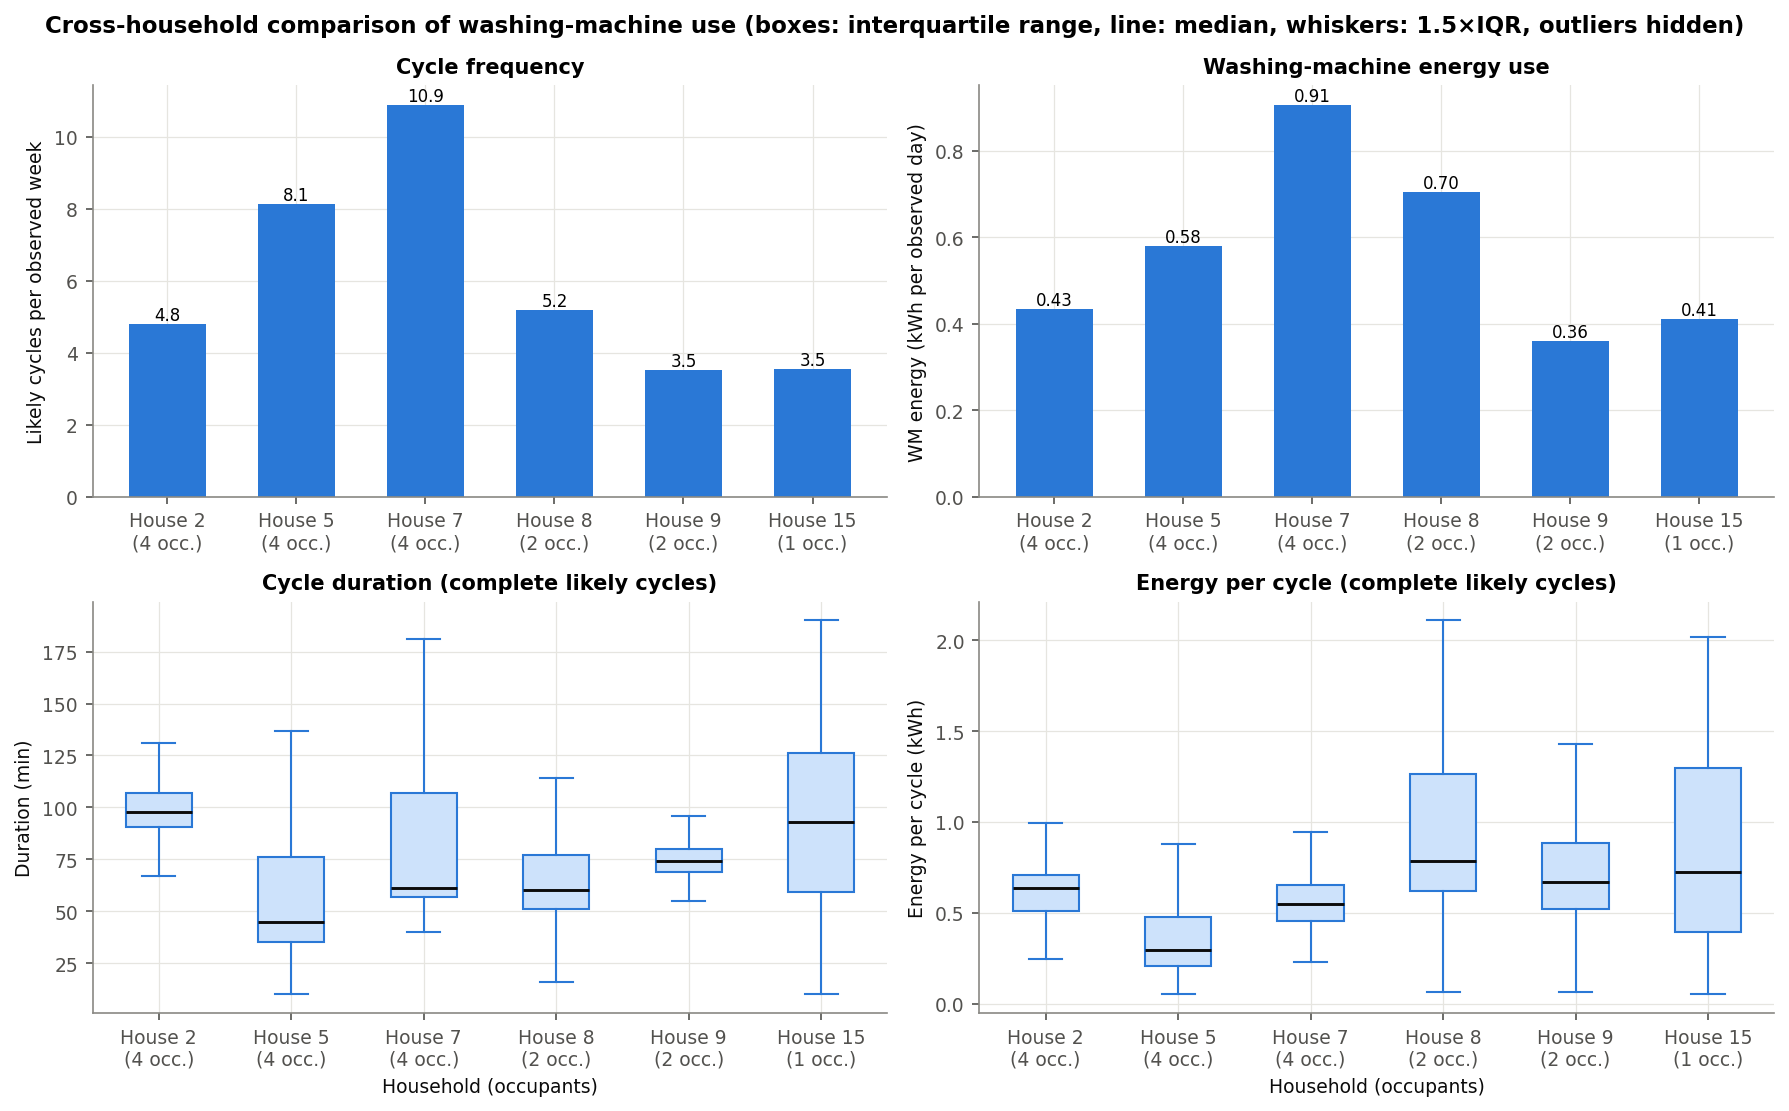

In [18]:
display(Image(filename=str(w.fig_cross_house(summary, act))))

**Interpretation (only what the data support).**

- **Frequency scales loosely with occupancy, but not reliably.** The two most frequent users are
  4-person homes (Houses 7 and 5), but House 2 — also 4 people — washes about as often as the 2-person
  House 8. Per occupant, the single-person House 15 is the highest. Occupancy alone does not predict use.
- **Energy per cycle varies by a factor of ~2–3 between houses** (median ~0.3–0.8 kWh). Almost every complete
  cycle includes a heating phase, so the spread mostly reflects heating time / wash temperature and programme
  choice, plus machine model.
- **House 7 uses the most washing-machine energy** because it runs the most cycles, not because its cycles are
  large. **House 8** runs fewer cycles but the largest ones. House 5's low per-cycle energy and wide spread are
  likely affected by the washer-dryer issue.
- **The washing machine is a small share of total household electricity** (a few percent of aggregate energy
  in every house), but it is a concentrated, schedulable ~2 kW load — relevant to peak-shifting rather than to
  total-consumption reduction.

> **Limitation:** six homes from one area of the UK over ~1.5 years are not a representative sample; the
> differences above describe these homes and should not be generalised to a population.

## 7 · Save outputs and headline numbers

All tables are written to `outputs/tables/phase2/`. `12_key_numbers.csv` holds the headline numbers quoted
in `phase2/RESULTS.md`, so the report can be checked against a fresh run.

In [19]:
res = dict(minute=minute, checks=checks, quality=quality, gaps=gaps, daily=daily, act=act, sens=sens,
           hourly=hourly, weekly=weekly, summary=summary, reps=reps, rep_day=rep_day)
for p in w.save_tables(res):
    print("saved", p.relative_to(w.ROOT))
w.key_numbers(res)

saved outputs/tables/phase2/01_household_channel_mapping.csv
saved outputs/tables/phase2/02_integrity_checks.csv
saved outputs/tables/phase2/03_availability_quality_summary.csv
saved outputs/tables/phase2/04_gaps_over_1h.csv
saved outputs/tables/phase2/05_activity_periods_all.csv
saved outputs/tables/phase2/06_cycle_summary_by_house.csv
saved outputs/tables/phase2/07_hourly_profile.csv
saved outputs/tables/phase2/08_weekday_profile.csv
saved outputs/tables/phase2/09_threshold_sensitivity.csv
saved outputs/tables/phase2/10_representative_cycles.csv
saved outputs/tables/phase2/11_representative_day.csv
saved outputs/tables/phase2/12_key_numbers.csv


,metric,value
0,houses_analysed,6.000
1,total_activity_periods,3404.000
2,total_likely_cycles,2678.000
3,total_complete_cycles,2472.000
4,availability_pct_min,75.380
5,availability_pct_max,89.730
6,cycles_per_week_min,3.520
7,cycles_per_week_max,10.880
8,median_cycle_kwh_min,0.293
9,median_cycle_kwh_max,0.786
